<a href="https://colab.research.google.com/github/ibnu-aulia/arabic-text-analyzer/blob/main/arabic_reviews_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Arabic Reviews: Exploratory Data Analysis
Finding the most frequent words and checking correlations between text features.

In [1]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# 1. Reload the dataset (if the old dataframe is still in memory, you can skip this)
df = pd.read_csv('ar_reviews_100k.tsv', sep='\t')
df = df[df['label'] != 'Mixed']# remove the "Mixed" label.

# 2. Make a new CountVectorizer, specifically for EDA
cv_eda = CountVectorizer()
eda_result = cv_eda.fit_transform(df['text'])

# 3. Sum up the occurrences of each word (go down by column)
word_count = eda_result.sum(axis=0)

In [2]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

stopword_arab = stopwords.words('arabic')
print(stopword_arab[:10])

['إذ', 'إذا', 'إذما', 'إذن', 'أف', 'أقل', 'أكثر', 'ألا', 'إلا', 'التي']


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [3]:
print(word_count)

[[1 1 2 ... 1 2 1]]


In [4]:
word_name = cv_eda.get_feature_names_out()
print(word_name[:10]) # just look at the first 10 words, to check

['ءأنت' 'ءافرادا' 'ءالآء' 'ءامنت' 'ءامنوا' 'ءغرف' 'ءموظفى' 'ءوءو' 'ءوجبة'
 'آآآآآآآآآآآآآآآآآآآآآآآآآه']


In [5]:
flat_word_count = word_count.A1

In [6]:
print(flat_word_count[:10])

[1 1 2 1 1 1 1 1 1 1]


In [7]:
partner = list(zip(word_name, flat_word_count))
running_pair = sorted(partner, key=lambda x: x[1], reverse=True)
top_10 = running_pair[:10]
print(top_10)

[('من', np.int64(85918)), ('في', np.int64(78337)), ('لا', np.int64(33118)), ('على', np.int64(32202)), ('أن', np.int64(25307)), ('جدا', np.int64(24909)), ('ما', np.int64(24392)), ('عن', np.int64(23852)), ('لم', np.int64(19759)), ('ان', np.int64(18047))]


In [8]:
cv_clean = CountVectorizer(stop_words=stopword_arab)
clean_result = cv_clean.fit_transform(df['text'])

clean_word_count = clean_result.sum(axis=0).A1
clean_word_name = cv_clean.get_feature_names_out()

clean_couple = list(zip(clean_word_name, clean_word_count))
top_10_clean = sorted(clean_couple, key=lambda x: x[1], reverse=True)[:10]
print(top_10_clean)

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['آمين', 'أب', 'أخ', 'أفعل', 'أفعله', 'ؤلاء', 'إل', 'إم', 'ات', 'اتان', 'ارتد', 'ان', 'انفك', 'برح', 'تان', 'تبد', 'تحو', 'تعل', 'حد', 'حم', 'حي', 'خب', 'ذار', 'سيما', 'صه', 'ظل', 'ظن', 'عد', 'قط', 'مر', 'مكان', 'مكانكن', 'نب', 'هات', 'هب', 'واها', 'وراء'] not in stop_words.
  warnings.warn(


[('جدا', np.int64(24909)), ('ان', np.int64(18047)), ('الرواية', np.int64(16550)), ('الكتاب', np.int64(16548)), ('فى', np.int64(15269)), ('الفندق', np.int64(12206)), ('كانت', np.int64(9477)), ('الكاتب', np.int64(8070)), ('كتاب', np.int64(7774)), ('الله', np.int64(7724))]


In [9]:
# Cell 1
import matplotlib.pyplot as plt

word = [partner[0] for partner in top_10_clean]
amount = [partner[1] for partner in top_10_clean]

In [10]:
# Cell 2
!pip install arabic_reshaper python-bidi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [arabic_reshaper]


In [11]:
# Cell 3
import arabic_reshaper
from bidi.algorithm import get_display

fixed_word = [get_display(arabic_reshaper.reshape(k)) for k in word]

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 65010 (\N{ARABIC LIGATURE ALLAH ISOLATED FORM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


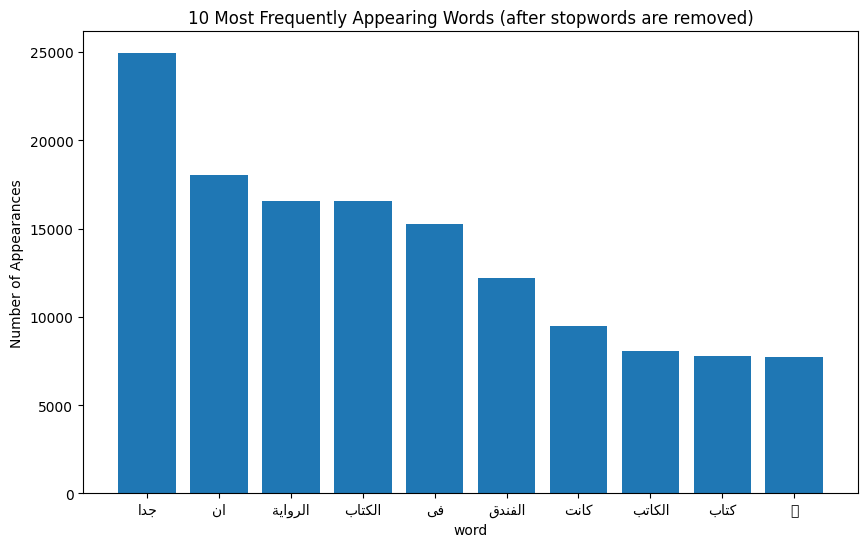

In [12]:
# Cell 4 — # use the reshaped Arabic labels so they render correctly.
plt.figure(figsize=(10, 6))
plt.bar(fixed_word, amount)
plt.title('10 Most Frequently Appearing Words (after stopwords are removed)')
plt.xlabel('word')
plt.ylabel('Number of Appearances')
plt.show()

In [13]:
df['word_count'] = df['text'].str.split().str.len()
df['letter_count'] = df['text'].str.len()
df['average_word_length'] = df['letter_count'] / df['word_count']

In [14]:
df[['word_count', 'letter_count', 'average_word_length']].head()

,word_count,letter_count,average_word_length
0,9,57,6.333333
1,53,273,5.150943
2,48,255,5.312500
3,107,572,5.345794
4,15,74,4.933333


In [15]:
correlation = df[['word_count', 'letter_count', 'average_word_length']].corr()
print(correlation)

                     word_count  letter_count  average_word_length
word_count             1.000000      0.997658            -0.025212
letter_count           0.997658      1.000000            -0.001859
average_word_length   -0.025212     -0.001859             1.000000


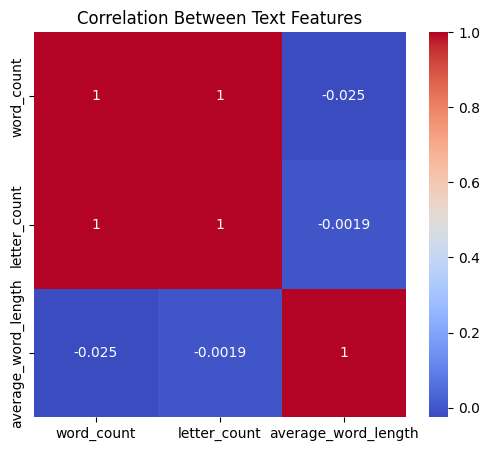

In [16]:
import seaborn as sns

plt.figure(figsize=(6, 5))
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title('Correlation Between Text Features')
plt.show()

- word_count and letter_count are almost perfectly correlated (~0.998),
  because more words means more letters.